# Mamíferos de Colombia — Fase B: entrenamiento del modelo (40 clases)
### Transfer Learning con EfficientNetV2 · Data Augmentation · Dropout + L2 · EarlyStopping · 10 + 50 épocas · meta ≥ 94 %

**Aplicación en la región:** clasificar automáticamente las fotos de **cámaras trampa del Tolima** en 40 especies de mamíferos (6 endémicas, 10 amenazadas). Usos: monitoreo de especies amenazadas, conflicto fauna–campesinos (¿puma, jaguar o perro feral?) y detección de perros y gatos ferales en reservas.

**Pipeline completo**

| Fase | Notebook | Qué hace |
|---|---|---|
| A | `Mamiferos_Colombia_40_Clases_Dataset` | Descarga desde GBIF/NaturaLista, limpieza técnica (dañadas, pequeñas, duplicados SHA-256 y pHash), selección y recorte con **YOLO (MegaDetector V6)**, estándares de calidad (nitidez, brillo, contraste, exposición). Resultado: 23.374 imágenes |
| **B** | **este notebook** | Ingesta y auditoría → división por registro → *Data Augmentation* → *Transfer Learning* → evaluación con fotos de Colombia |
| C | (siguiente) | Destilación a MobileNetV3, conversión a TFLite para celular, ensambles, pruebas con fotos reales del Tolima |

**Cómo ejecutarlo (Kaggle, GPU gratis):** panel derecho → *Session options* → **Accelerator: GPU T4 x2** e **Internet: On**; en *Input* agregar el dataset `mamiferos-colombia-40`.
Prueba corta: `MODO_PRUEBA = True` → *Run All*. Corrida completa: `MODO_PRUEBA = False` → **Save Version → Save & Run All (Commit)**: corre en los servidores de Kaggle aunque se cierre el navegador, y todo lo que produce (modelo, historial, gráficos, log) queda en la pestaña **Output** de esa versión.

---
# 0. Configuración

In [1]:
# 0.1 CONFIGURACIÓN (todas las decisiones del modelo están aquí)
import os, sys, io, json, time, math, random, shutil, zipfile, hashlib, logging, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

EN_KAGGLE = Path("/kaggle/input").exists()

# ---------- Datos ----------
FRAC_VAL, FRAC_TEST = 0.15, 0.15       # validación y prueba: SOLO fotos de Colombia, separadas por registro (gbifID)
MAX_TRAIN_POR_CLASE = 1200             # tope en entrenamiento para que la ardilla colirroja (2.452) no domine

# ---------- Modelo profesor (Transfer Learning) ----------
MODELO_BASE = "EfficientNetV2S"        # opciones: EfficientNetV2S, EfficientNetV2B3, EfficientNetB3, ResNet50V2, MobileNetV3Large
IMG_SIZE = 260
BATCH = 32
DENSA = 512                            # neuronas de la capa densa antes de la salida
DROPOUT_1, DROPOUT_2 = 0.40, 0.30      # anti-overfitting
REGULARIZACION, FACTOR_REG = "l2", 1e-4   # "l1", "l2", "l1_l2" o None  (penaliza los pesos grandes)
LABEL_SMOOTHING = 0.10

# ---------- Entrenamiento ----------
EPOCAS_ETAPA1 = 10                     # etapa 1: base congelada, solo se entrena la cabeza
EPOCAS_TOTALES = 60                    # etapa 2: ajuste fino de la parte alta de la base (épocas 11 a 60 = 50 épocas)
LR_ETAPA1, LR_ETAPA2 = 1e-3, 1e-4      # optimizador Adam
FRACCION_AJUSTE_FINO = 0.60
PACIENCIA = 12
EPOCA_MINIMA = 50                       # EarlyStopping: para si val_accuracy no mejora en 10 épocas
META_ACCURACY = 0.94

MODO_PRUEBA = False                   # True = corrida corta de demostración (pocos lotes, 2 épocas) para verificar el pipeline
SEED = 42
random.seed(SEED); np.random.seed(SEED)

print("Kaggle:", EN_KAGGLE, "| modelo:", MODELO_BASE, f"{IMG_SIZE}px | épocas: {EPOCAS_ETAPA1} + {EPOCAS_TOTALES - EPOCAS_ETAPA1} = {EPOCAS_TOTALES}",
      "| MODO_PRUEBA" if MODO_PRUEBA else "")

Kaggle: True | modelo: EfficientNetV2S 260px | épocas: 10 + 50 = 60 


In [2]:
# 0.2 Entorno: GPU, TensorFlow/Keras, carpetas de salida y LOG
import tensorflow as tf
import keras
from keras import layers, regularizers
from IPython.display import display

BASE_SALIDA = Path("/kaggle/working") if EN_KAGGLE else Path.cwd()
SALIDA = BASE_SALIDA / ("entrenamiento_prueba" if MODO_PRUEBA else "entrenamiento")   # la prueba no mezcla sus archivos con los reales
EVI = SALIDA / "evidencia"
for p in [SALIDA, EVI, SALIDA / "logs"]:
    p.mkdir(parents=True, exist_ok=True)

log = logging.getLogger("ENTRENAMIENTO"); log.setLevel(logging.INFO); log.handlers.clear(); log.propagate = False
_fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%Y-%m-%d %H:%M:%S")
_fh = logging.FileHandler(SALIDA / "logs" / f"entrenamiento_{datetime.now():%Y%m%d_%H%M%S}.log", encoding="utf-8")
_sh = logging.StreamHandler(sys.stdout)
for h in (_fh, _sh):
    h.setFormatter(_fmt); log.addHandler(h)

GPUS = tf.config.list_physical_devices("GPU")
if GPUS:
    keras.mixed_precision.set_global_policy("mixed_float16")     # ~2x más rápido en GPU T4
keras.utils.set_random_seed(SEED)
log.info("=" * 70)
log.info(f"SESIÓN DE ENTRENAMIENTO | TensorFlow {tf.__version__} | Keras {keras.__version__} | "
         f"GPU: {[g.name for g in GPUS] or 'NINGUNA'} | precisión: {keras.mixed_precision.global_policy().name}")
log.info(f"Salidas en: {SALIDA}")
if not GPUS:
    print("⚠️  No hay GPU. Panel derecho → Session options → Accelerator: GPU T4 x2 (requiere celular verificado).")

2026-10-13 03:27:46 | INFO    | ======================================================================
2026-10-13 03:27:46 | INFO    | SESIÓN DE ENTRENAMIENTO | TensorFlow 2.20.0 | Keras 3.13.2 | GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1'] | precisión: mixed_float16
2026-10-13 03:27:46 | INFO    | Salidas en: /kaggle/working/entrenamiento


---
# 1. Ingesta de las 40 clases y auditoría automática
Las imágenes vienen de la **Fase A** (búsqueda en GBIF → limpieza técnica → YOLO → estándares de calidad).
Aquí se **vuelven a auditar** antes de entrenar: archivos dañados, tamaño mínimo y duplicados exactos (SHA-256).

In [3]:
# 1.1 Ingesta: ubicar el dataset subido a Kaggle (Kaggle descomprime el ZIP solo) y leer metadata.csv
RAIZ = Path("/kaggle/input") if EN_KAGGLE else Path.cwd()
encontrados = sorted(RAIZ.rglob("metadata.csv"))
if encontrados:
    DATOS = encontrados[0].parent
else:                                                  # por si el ZIP no se descomprimió
    zips = sorted(RAIZ.rglob("*.zip"))
    assert zips, "No encuentro el dataset. Panel derecho → Input → Add Input → Your Datasets → mamiferos-colombia-40"
    DATOS = Path("/tmp/datos")
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(DATOS)
meta = pd.read_csv(DATOS / "metadata.csv")
carpeta_img = DATOS / "dataset" if (DATOS / "dataset").exists() else DATOS
meta["ruta"] = meta["archivo"].map(lambda a: str(carpeta_img / a))
log.info(f"Dataset en: {DATOS}")
log.info(f"INGESTA: {len(meta)} imágenes | {meta.clase.nunique()} clases | "
         f"Colombia {int((meta.origen == 'colombia').sum())} | Latinoamérica {int((meta.origen != 'colombia').sum())}")

2026-10-13 03:28:07 | INFO    | Dataset en: /kaggle/input/datasets/davida29/mamiferos-colombia-40
2026-10-13 03:28:07 | INFO    | INGESTA: 23374 imágenes | 40 clases | Colombia 16147 | Latinoamérica 7227


In [4]:
# 1.2 Auditoría automática de la ingesta (limpieza antes de entrenar)
def auditar(ruta):
    p = Path(ruta)
    if not p.exists():
        return "no_existe", ""
    data = p.read_bytes()
    try:
        with Image.open(io.BytesIO(data)) as im:
            im.verify()
        with Image.open(io.BytesIO(data)) as im:
            w, h = im.size
    except Exception:
        return "corrupta", ""
    if min(w, h) < 64:
        return "muy_pequena", ""
    return "", hashlib.sha256(data).hexdigest()

t0 = time.time()
res = [auditar(r) for r in meta["ruta"]]
meta["problema"] = [r[0] for r in res]; meta["sha256"] = [r[1] for r in res]
dup = meta["sha256"].ne("") & meta.duplicated("sha256", keep="first")
meta.loc[dup, "problema"] = "duplicado_exacto"
aud = meta["problema"].replace("", "OK").value_counts()
log.info(f"AUDITORÍA ({time.time() - t0:.0f} s): " + " | ".join(f"{k}={v}" for k, v in aud.items()))
display(aud.to_frame("imágenes"))
meta = meta[meta["problema"] == ""].reset_index(drop=True)

CLASES = sorted(meta["clase"].unique())
N_CLASES = len(CLASES)
IDX = {c: i for i, c in enumerate(CLASES)}
meta["y"] = meta["clase"].map(IDX)
NOMBRE = meta.drop_duplicates("clase").set_index("clase")["nombre_comun"].to_dict()
log.info(f"Imágenes válidas para entrenar: {len(meta)} | clases: {N_CLASES}")

2026-10-13 03:29:25 | INFO    | AUDITORÍA (78 s): OK=23358 | muy_pequena=16


,imágenes
problema,
OK,23358
muy_pequena,16


2026-10-13 03:29:25 | INFO    | Imágenes válidas para entrenar: 23358 | clases: 40


,nombre,imagenes,registros_gbif,colombia,latinoamerica,endemica,uicn
clase,,,,,,,
ardilla_colirroja,Ardilla colirroja,2452,1879,2452,0,False,LC
neque,Ñeque,924,729,924,0,False,LC
mono_aullador_rojo,Mono aullador rojo,891,656,891,0,False,LC
gato_domestico_feral,Gato doméstico o feral,846,621,189,657,False,LC
perro_domestico_feral,Perro doméstico o feral,797,650,237,560,False,LC
mono_churuco,Mono churuco,778,536,162,616,False,VU
danta,Danta,746,555,204,542,False,VU
venado_cola_blanca,Venado cola blanca,744,553,744,0,False,LC
oso_de_anteojos,Oso de anteojos,668,451,97,571,False,VU


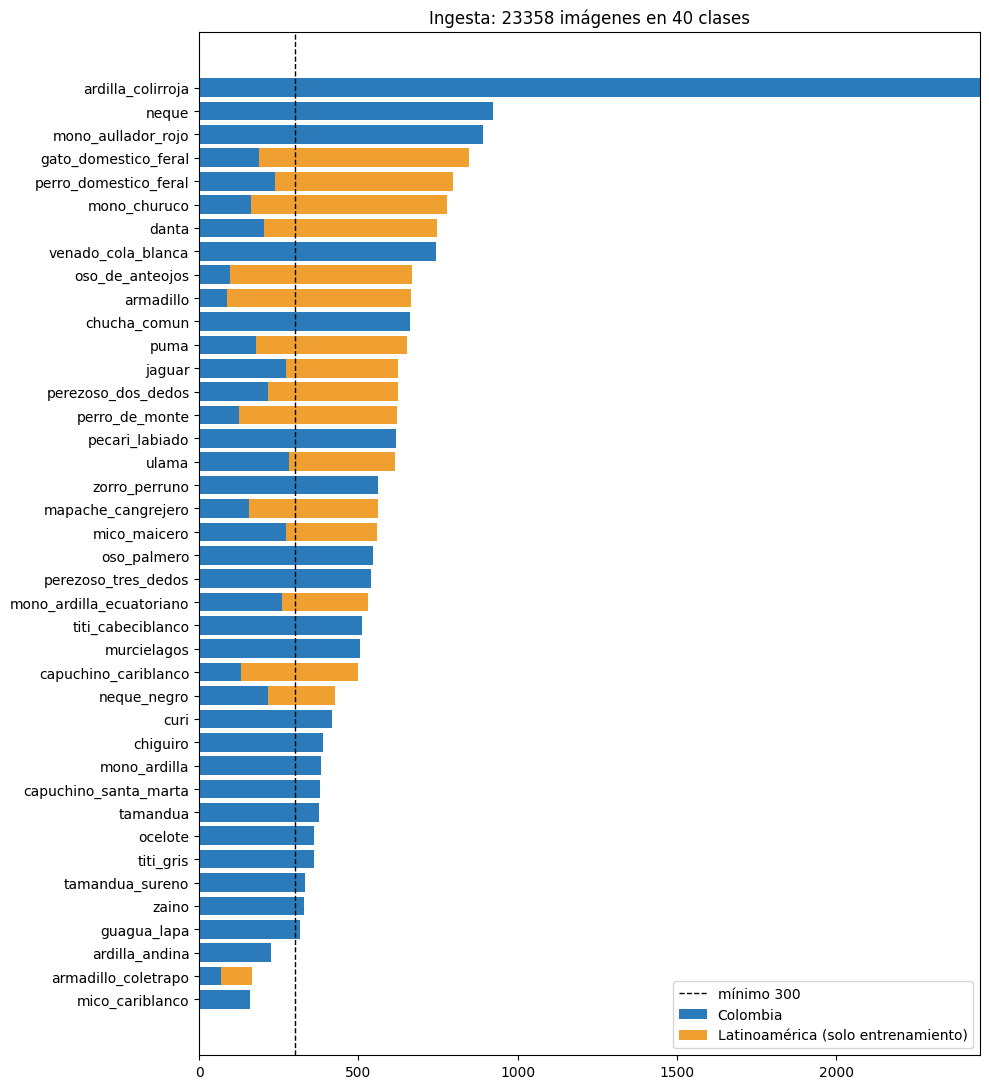

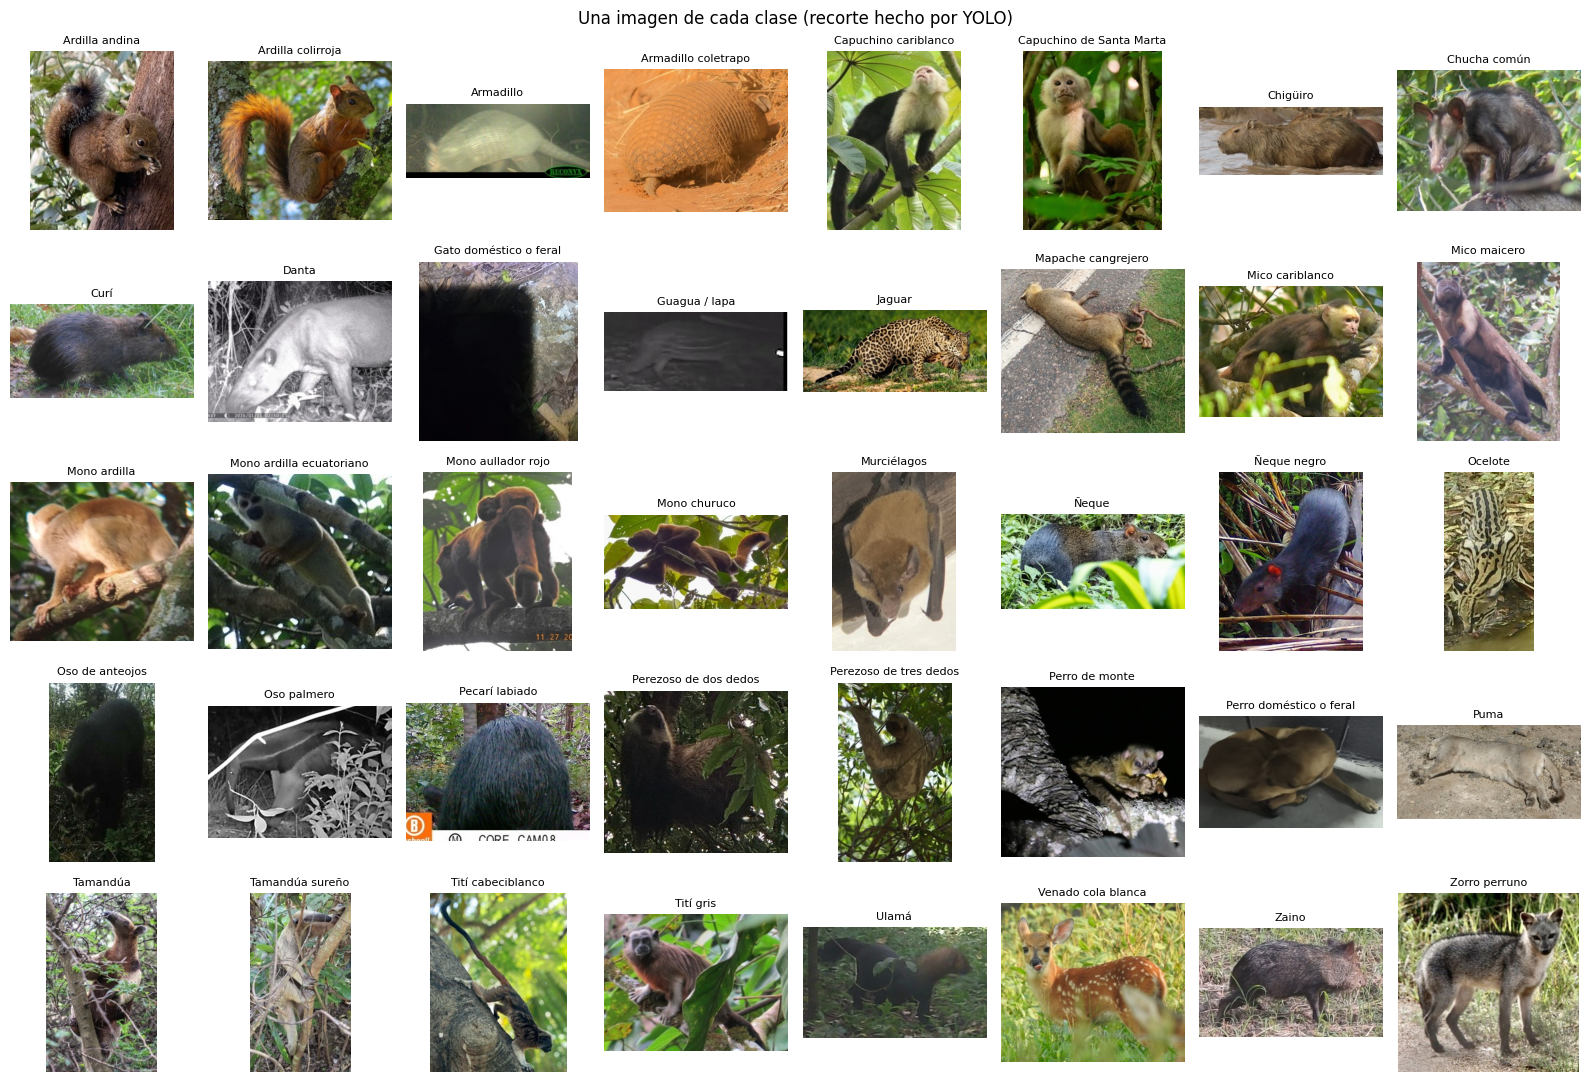

In [5]:
# 1.3 Resumen por clase (evidencia de la ingesta) + una imagen de cada clase
resumen = (meta.groupby("clase")
               .agg(nombre=("nombre_comun", "first"), imagenes=("archivo", "count"),
                    registros_gbif=("gbifID", "nunique"),
                    colombia=("origen", lambda s: int((s == "colombia").sum())),
                    latinoamerica=("origen", lambda s: int((s != "colombia").sum())),
                    endemica=("endemica", "first"), uicn=("uicn", "first"))
               .sort_values("imagenes", ascending=False))
display(resumen)
resumen.to_csv(EVI / "ingesta_resumen_por_clase.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(10, 11))
r2 = resumen.sort_values("imagenes")
ax.barh(r2.index, r2["colombia"], color="#2b7bba", label="Colombia")
ax.barh(r2.index, r2["latinoamerica"], left=r2["colombia"], color="#f0a030", label="Latinoamérica (solo entrenamiento)")
ax.axvline(300, ls="--", c="k", lw=1, label="mínimo 300"); ax.legend(loc="lower right")
ax.set_title(f"Ingesta: {len(meta)} imágenes en {N_CLASES} clases"); plt.tight_layout()
plt.savefig(EVI / "ingesta_imagenes_por_clase.png", dpi=110); plt.show()

fig, axs = plt.subplots(5, 8, figsize=(16, 11))
for ax, c in zip(axs.ravel(), CLASES):
    ax.imshow(Image.open(meta[meta.clase == c].sample(1, random_state=SEED)["ruta"].iloc[0])); ax.axis("off")
    ax.set_title(NOMBRE[c], fontsize=8)
for ax in axs.ravel()[N_CLASES:]:
    ax.axis("off")
plt.suptitle("Una imagen de cada clase (recorte hecho por YOLO)"); plt.tight_layout()
plt.savefig(EVI / "ingesta_una_por_clase.png", dpi=90); plt.show()

---
# 2. División entrenamiento / validación / prueba
- **Por registro (gbifID):** las fotos de un mismo avistamiento quedan todas en el mismo grupo. Si no, el modelo "vería" el mismo animal en entrenamiento y en prueba y la exactitud saldría inflada (*fuga de datos*).
- **Validación y prueba solo con fotos de Colombia.** Las fotos de otros países de Latinoamérica (aprobadas por el profesor) se usan **solo para entrenar**. Así la exactitud reportada es la de nuestra región.
- **Tope de 1.200 por clase** en entrenamiento y **pesos por clase** para compensar el desbalance (2.452 ardillas vs. 159 micos cariblancos).

In [6]:
# 2.1 División estratificada por clase y agrupada por registro GBIF
rng = np.random.default_rng(SEED)
meta["split"] = "train"
for c, d in meta.groupby("clase"):
    reg_fuera = set(d.loc[d["origen"] != "colombia", "gbifID"])     # registros de otros países: solo entrenamiento
    col = d[~d["gbifID"].isin(reg_fuera)]
    por_reg = col.groupby("gbifID").size()
    ids = por_reg.index.to_numpy().copy(); rng.shuffle(ids)
    total, acum, asign = int(por_reg.sum()), 0, {}
    for g in ids:
        asign[g] = "test" if acum < total * FRAC_TEST else ("val" if acum < total * (FRAC_TEST + FRAC_VAL) else "train")
        acum += int(por_reg[g])
    meta.loc[col.index, "split"] = col["gbifID"].map(asign).values

# Tope por clase en entrenamiento (se priorizan las fotos de Colombia)
meta["_azar"] = rng.random(len(meta))
tr = meta[meta.split == "train"].sort_values(["clase", "origen", "_azar"],
                                             key=lambda s: (s != "colombia") if s.name == "origen" else s)
sobran = tr.groupby("clase").cumcount() >= MAX_TRAIN_POR_CLASE
meta.loc[tr.index[sobran.values], "split"] = "sin_usar"

# Verificación: ningún registro GBIF puede estar en dos grupos
g = {s: set(meta.loc[meta.split == s, "gbifID"]) for s in ["train", "val", "test"]}
assert not (g["train"] & g["val"]) and not (g["train"] & g["test"]) and not (g["val"] & g["test"]), "¡Fuga de datos!"
assert (meta.loc[meta.split.isin(["val", "test"]), "origen"] == "colombia").all()

tabla_split = pd.crosstab(meta["clase"], meta["split"]).reindex(columns=["train", "val", "test", "sin_usar"], fill_value=0)
display(tabla_split)
tabla_split.to_csv(EVI / "division_por_clase.csv", encoding="utf-8-sig")
meta.drop(columns=["_azar"]).to_csv(SALIDA / "division_dataset.csv", index=False, encoding="utf-8-sig")
cuenta = meta["split"].value_counts()
log.info("DIVISIÓN por gbifID (sin fuga de datos ✓): " + " | ".join(f"{k}={cuenta.get(k, 0)}" for k in ["train", "val", "test", "sin_usar"]))

split,train,val,test,sin_usar
clase,,,,
ardilla_andina,156,34,34,0
ardilla_colirroja,1200,366,370,516
armadillo,637,14,14,0
armadillo_coletrapo,145,9,12,0
capuchino_cariblanco,459,20,20,0
capuchino_santa_marta,263,57,58,0
chiguiro,271,58,59,0
chucha_comun,462,99,100,0
curi,292,63,63,0


2026-10-13 03:29:32 | INFO    | DIVISIÓN por gbifID (sin fuga de datos ✓): train=17960 | val=2424 | test=2458 | sin_usar=516


In [7]:
# 2.2 Pesos por clase (compensan el desbalance): peso = N / (K · n_clase), limitado entre 0.5 y 5
n_tr = meta[meta.split == "train"].groupby("y").size().reindex(range(N_CLASES), fill_value=1)
PESOS = np.clip(n_tr.sum() / (N_CLASES * n_tr), 0.5, 5.0)
meta["peso"] = meta["y"].map(PESOS)
display(pd.DataFrame({"clase": CLASES, "imagenes_train": n_tr.values, "peso": PESOS.round(2).values})
          .sort_values("peso", ascending=False).head(10))
log.info(f"Pesos por clase: mínimo {PESOS.min():.2f} ({CLASES[int(PESOS.idxmin())]}) | "
         f"máximo {PESOS.max():.2f} ({CLASES[int(PESOS.idxmax())]})")

,clase,imagenes_train,peso
14,mico_cariblanco,111,4.05
3,armadillo_coletrapo,145,3.10
0,ardilla_andina,156,2.88
11,guagua_lapa,219,2.05
38,zaino,231,1.94
33,tamandua_sureno,231,1.94
35,titi_gris,251,1.79
23,ocelote,251,1.79
32,tamandua,263,1.71
5,capuchino_santa_marta,263,1.71


2026-10-13 03:29:32 | INFO    | Pesos por clase: mínimo 0.50 (ardilla_colirroja) | máximo 4.05 (mico_cariblanco)


---
# 3. Canalización de datos (tf.data) y *Data Augmentation*
El aumento de datos se hace **dentro del modelo** (en la GPU) y **solo durante el entrenamiento**:

| Transformación | Por qué, pensando en cámaras trampa |
|---|---|
| Volteo horizontal | el animal puede pasar en cualquier dirección |
| Rotación ±8 %, zoom ±15 %, traslación ±8 % | la cámara no siempre queda recta y el animal está a distintas distancias |
| Contraste y brillo ±25 % | amanecer, sombra del bosque, flash |
| **Escala de grises (20 %)** | **de noche las cámaras trampa toman fotos infrarrojas en blanco y negro** |

In [8]:
# 3.1 Lectura eficiente con tf.data (paralela + prefetch)
AUTOTUNE = tf.data.AUTOTUNE

def leer_imagen(ruta, size):
    img = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)
    return tf.image.resize(img, (size, size), antialias=True)          # float32 en 0..255

def hacer_ds(df, size=IMG_SIZE, entrenamiento=False):
    if entrenamiento:
        ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, df["y"].values.astype("int32"),
                                                 df["peso"].values.astype("float32")))
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda r, y, w: (leer_imagen(r, size), tf.one_hot(y, N_CLASES), w), num_parallel_calls=AUTOTUNE)
    else:
        ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, df["y"].values.astype("int32")))
        ds = ds.map(lambda r, y: (leer_imagen(r, size), tf.one_hot(y, N_CLASES)), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

TRAIN = meta[meta.split == "train"].reset_index(drop=True)
VAL = meta[meta.split == "val"].reset_index(drop=True)
TEST = meta[meta.split == "test"].reset_index(drop=True)
ds_train, ds_val, ds_test = hacer_ds(TRAIN, entrenamiento=True), hacer_ds(VAL), hacer_ds(TEST)
if MODO_PRUEBA:
    ds_train, ds_val, ds_test = ds_train.take(15), ds_val.take(5), ds_test.take(5)
log.info(f"tf.data listo | train {len(TRAIN)} | val {len(VAL)} | test {len(TEST)} | lote {BATCH} | "
         f"{math.ceil(len(TRAIN) / BATCH)} pasos por época")

I0000 00:00:1791862172.828385      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791862172.832374      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


2026-10-13 03:29:35 | INFO    | tf.data listo | train 17960 | val 2424 | test 2458 | lote 32 | 562 pasos por época


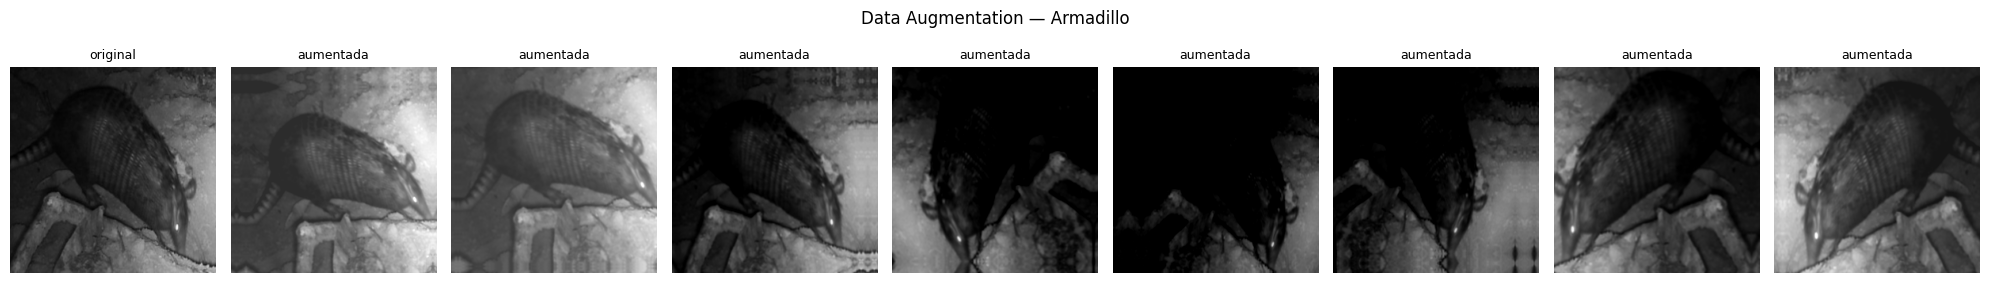

In [9]:
# 3.2 Capas de Data Augmentation (incluye una capa propia: escala de grises aleatoria)
class GrisAleatorio(layers.Layer):
    """Convierte a escala de grises una fracción p de las imágenes (simula fotos infrarrojas nocturnas)."""
    def __init__(self, p=0.2, **kwargs):
        super().__init__(**kwargs)
        self.p = p
    def call(self, x, training=None):
        if not training:
            return x
        gris = x[..., 0:1] * 0.299 + x[..., 1:2] * 0.587 + x[..., 2:3] * 0.114
        gris = tf.concat([gris, gris, gris], axis=-1)
        m = tf.cast(tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) < self.p, x.dtype)
        return m * gris + (1 - m) * x
    def get_config(self):
        return {**super().get_config(), "p": self.p}

def crear_aumento():
    f32 = dict(dtype="float32")
    return keras.Sequential([
        layers.RandomFlip("horizontal", **f32),
        layers.RandomRotation(0.08, fill_mode="reflect", **f32),
        layers.RandomZoom((-0.15, 0.15), fill_mode="reflect", **f32),
        layers.RandomTranslation(0.08, 0.08, fill_mode="reflect", **f32),
        layers.RandomContrast(0.25, **f32),
        layers.RandomBrightness(0.25, **f32),
        GrisAleatorio(0.20, **f32),
    ], name="aumento_de_datos")

# Ejemplo: la misma imagen con 8 aumentos distintos
aum = crear_aumento()
ej = leer_imagen(TRAIN["ruta"].iloc[0], IMG_SIZE)[None]
fig, axs = plt.subplots(1, 9, figsize=(20, 3))
axs[0].imshow(ej[0].numpy().astype("uint8")); axs[0].set_title("original", fontsize=9)
for ax in axs[1:]:
    ax.imshow(np.clip(aum(ej, training=True)[0].numpy(), 0, 255).astype("uint8")); ax.set_title("aumentada", fontsize=9)
for ax in axs: ax.axis("off")
plt.suptitle(f"Data Augmentation — {NOMBRE[TRAIN['clase'].iloc[0]]}"); plt.tight_layout()
plt.savefig(EVI / "data_augmentation_ejemplos.png", dpi=100); plt.show()

---
# 4. Modelo profesor: *Transfer Learning* con EfficientNetV2-S
- **Base:** EfficientNetV2-S preentrenada en ImageNet (1,2 millones de imágenes, 1.000 categorías). Ya sabe reconocer bordes, texturas, pelaje y formas; solo hay que enseñarle nuestras 40 especies.
- **Cabeza propia:** Dropout 0,4 → Densa 512 (ReLU, **regularización L2**) → Dropout 0,3 → salida de 40 clases.
- **Dos etapas:** (1) base congelada, se entrena solo la cabeza; (2) se descongela el 30 % final de la base y se ajusta con una tasa de aprendizaje 10 veces menor (*fine-tuning*). Las capas BatchNormalization se dejan congeladas para no dañar lo aprendido.
- **Pérdida:** entropía cruzada con *label smoothing* 0,1 (el modelo no se vuelve sobreconfiado, útil con especies parecidas).

In [10]:
# 4.1 Construcción del modelo
BASES = {
    "EfficientNetV2S": keras.applications.EfficientNetV2S,
    "EfficientNetV2B3": keras.applications.EfficientNetV2B3,
    "EfficientNetB3": keras.applications.EfficientNetB3,
    "ResNet50V2": keras.applications.ResNet50V2,
    "MobileNetV3Large": keras.applications.MobileNetV3Large,
}
ESCALA_MENOS1_A_1 = {"ResNet50V2"}          # las demás normalizan la imagen por dentro (entrada 0..255)

def regularizador():
    return {"l1": regularizers.L1(FACTOR_REG), "l2": regularizers.L2(FACTOR_REG),
            "l1_l2": regularizers.L1L2(l1=FACTOR_REG, l2=FACTOR_REG)}.get(REGULARIZACION)

def construir_modelo(nombre_base=MODELO_BASE, size=IMG_SIZE, nombre="profesor"):
    base = BASES[nombre_base](include_top=False, weights="imagenet", input_shape=(size, size, 3), pooling="avg")
    base.trainable = False
    entrada = keras.Input((size, size, 3), name="imagen")
    x = crear_aumento()(entrada)
    if nombre_base in ESCALA_MENOS1_A_1:
        x = layers.Rescaling(1 / 127.5, offset=-1)(x)
    x = base(x, training=False)                                   # BatchNorm de la base siempre en modo inferencia
    x = layers.Dropout(DROPOUT_1, name="dropout_1")(x)
    x = layers.Dense(DENSA, activation="relu", kernel_regularizer=regularizador(), name="densa")(x)
    x = layers.Dropout(DROPOUT_2, name="dropout_2")(x)
    salida = layers.Dense(N_CLASES, kernel_regularizer=regularizador(), dtype="float32", name="logits")(x)
    return keras.Model(entrada, salida, name=nombre), base

def compilar(modelo, lr):
    modelo.compile(optimizer=keras.optimizers.Adam(lr),
                   loss=keras.losses.CategoricalCrossentropy(from_logits=True, label_smoothing=LABEL_SMOOTHING),
                   metrics=[keras.metrics.CategoricalAccuracy(name="accuracy"),
                            keras.metrics.TopKCategoricalAccuracy(k=3, name="top3")])

profesor, base = construir_modelo()
compilar(profesor, LR_ETAPA1)
profesor.summary(show_trainable=True)
n_entrenables = sum(int(np.prod(w.shape)) for w in profesor.trainable_weights)
log.info(f"MODELO: {MODELO_BASE} + cabeza propia | parámetros totales {profesor.count_params():,} | "
         f"entrenables en etapa 1: {n_entrenables:,} | capas de la base: {len(base.layers)}")

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "profesor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ imagen (InputLayer)         │ (None, 260, 260, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ aumento_de_datos            │ (None, 260, 260, 3)   │          0 │   -   │
│ (Sequential)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetv2-s            │ (None, 1280)          │ 20,331,360 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_1 (Dropout)         │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ densa (Dense)               │ (None, 512)           │    655,872 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_2 (Dropout)         │ (None, 512)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ logits (Dense)              │ (None, 40)            │     20,520 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 21,007,752 (80.14 MB)

 Trainable params: 676,392 (2.58 MB)

 Non-trainable params: 20,331,360 (77.56 MB)

2026-10-13 03:29:48 | INFO    | MODELO: EfficientNetV2S + cabeza propia | parámetros totales 21,007,752 | entrenables en etapa 1: 676,392 | capas de la base: 514


In [11]:
# 4.2 Callbacks: EarlyStopping, mejor modelo, ajuste de la tasa de aprendizaje, historial, respaldo y log
class RegistroLog(keras.callbacks.Callback):
    def __init__(self, etapa):
        super().__init__(); self.etapa = etapa; self.t = 0
    def on_epoch_begin(self, epoch, logs=None):
        self.t = time.time()
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        log.info(f"[{self.etapa}] época {epoch + 1:02d}/{EPOCAS_TOTALES} | " +
                 " | ".join(f"{k}={float(v):.4f}" for k, v in logs.items()) + f" | {time.time() - self.t:.0f} s")

def crear_callbacks(etapa, umbral=None):
    return [
        keras.callbacks.ModelCheckpoint(str(SALIDA / "profesor_mejor.keras"), monitor="val_accuracy", mode="max",
                                        save_best_only=True, initial_value_threshold=umbral, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=PACIENCIA, min_delta=0,
                                      start_from_epoch=EPOCA_MINIMA, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=4, min_lr=1e-7, verbose=1),
        keras.callbacks.CSVLogger(str(SALIDA / f"historial_{etapa}.csv"), append=True),
        keras.callbacks.BackupAndRestore(str(SALIDA / f"respaldo_{etapa}")),   # si Colab se cae, continúa aquí
        RegistroLog(etapa),
    ]
print("Callbacks listos: ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger, BackupAndRestore, log")

Callbacks listos: ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger, BackupAndRestore, log


---
# 5. Entrenamiento (10 + 50 épocas)
La etapa 2 está configurada hasta la época 60. **EarlyStopping** la detiene antes si la exactitud de validación deja de mejorar durante 10 épocas, y recupera los mejores pesos: eso es justamente lo que evita el sobreajuste.

In [12]:
# 5.1 ETAPA 1 — base congelada, se entrena la cabeza
F_ETAPA1 = SALIDA / "etapa1_completa.weights.h5"
if F_ETAPA1.exists() and not MODO_PRUEBA:
    profesor.load_weights(F_ETAPA1)
    EPOCAS_HECHAS = len(pd.read_csv(SALIDA / "historial_etapa1.csv").drop_duplicates("epoch"))
    log.info(f"Etapa 1 ya estaba terminada ({EPOCAS_HECHAS} épocas): se cargan sus pesos y se continúa.")
else:
    log.info(f"ETAPA 1: {EPOCAS_ETAPA1 if not MODO_PRUEBA else 1} épocas con la base congelada | Adam lr={LR_ETAPA1}")
    h1 = profesor.fit(ds_train, validation_data=ds_val, epochs=EPOCAS_ETAPA1 if not MODO_PRUEBA else 1,
                      callbacks=crear_callbacks("etapa1"), verbose=2)
    EPOCAS_HECHAS = len(h1.epoch) if MODO_PRUEBA else len(pd.read_csv(SALIDA / "historial_etapa1.csv").drop_duplicates("epoch"))
    if not MODO_PRUEBA:
        profesor.save_weights(F_ETAPA1)
MEJOR_ETAPA1 = float(pd.read_csv(SALIDA / "historial_etapa1.csv")["val_accuracy"].max())
log.info(f"Fin etapa 1: {EPOCAS_HECHAS} épocas | mejor val_accuracy {MEJOR_ETAPA1:.4f}")

2026-10-13 03:29:48 | INFO    | ETAPA 1: 10 épocas con la base congelada | Adam lr=0.001
Epoch 1/10

Epoch 1: val_accuracy improved from None to 0.80776, saving model to /kaggle/working/entrenamiento/profesor_mejor.keras

Epoch 1: finished saving model to /kaggle/working/entrenamiento/profesor_mejor.keras
2026-10-13 03:32:47 | INFO    | [etapa1] época 01/60 | accuracy=0.6253 | loss=1.9473 | top3=0.8280 | val_accuracy=0.8078 | val_loss=1.3448 | val_top3=0.9480 | learning_rate=0.0010 | 178 s
562/562 - 178s - 318ms/step - accuracy: 0.6253 - loss: 1.9473 - top3: 0.8280 - val_accuracy: 0.8078 - val_loss: 1.3448 - val_top3: 0.9480 - learning_rate: 0.0010
Epoch 2/10

Epoch 2: val_accuracy improved from 0.80776 to 0.82343, saving model to /kaggle/working/entrenamiento/profesor_mejor.keras

Epoch 2: finished saving model to /kaggle/working/entrenamiento/profesor_mejor.keras
2026-10-13 03:34:48 | INFO    | [etapa1] época 02/60 | accuracy=0.7040 | loss=1.7008 | top3=0.8842 | val_accuracy=0.8234 |

In [13]:
# 5.2 ETAPA 2 — fine-tuning: se descongela el 30 % final de la base (BatchNorm sigue congelada)
base.trainable = True
corte = int(len(base.layers) * (1 - FRACCION_AJUSTE_FINO))
for i, capa in enumerate(base.layers):
    capa.trainable = (i >= corte) and not isinstance(capa, layers.BatchNormalization)
compilar(profesor, LR_ETAPA2)
n_entrenables = sum(int(np.prod(w.shape)) for w in profesor.trainable_weights)
fin = EPOCAS_TOTALES if not MODO_PRUEBA else EPOCAS_HECHAS + 1
log.info(f"ETAPA 2: fine-tuning desde la capa {corte}/{len(base.layers)} | parámetros entrenables {n_entrenables:,} | "
         f"Adam lr={LR_ETAPA2} | épocas {EPOCAS_HECHAS + 1} a {fin}")
h2 = profesor.fit(ds_train, validation_data=ds_val, epochs=fin, initial_epoch=EPOCAS_HECHAS,
                  callbacks=crear_callbacks("etapa2", umbral=MEJOR_ETAPA1), verbose=2)
log.info(f"Fin etapa 2: {len(h2.epoch)} épocas ejecutadas en esta sesión")

2026-10-13 03:50:44 | INFO    | ETAPA 2: fine-tuning desde la capa 205/514 | parámetros entrenables 17,667,968 | Adam lr=0.0001 | épocas 11 a 60
Epoch 11/60

Epoch 11: val_accuracy improved from 0.86139 to 0.88531, saving model to /kaggle/working/entrenamiento/profesor_mejor.keras

Epoch 11: finished saving model to /kaggle/working/entrenamiento/profesor_mejor.keras
2026-10-13 03:55:14 | INFO    | [etapa2] época 11/60 | accuracy=0.8148 | loss=1.4150 | top3=0.9403 | val_accuracy=0.8853 | val_loss=1.1689 | val_top3=0.9761 | learning_rate=0.0001 | 269 s
562/562 - 269s - 479ms/step - accuracy: 0.8148 - loss: 1.4150 - top3: 0.9403 - val_accuracy: 0.8853 - val_loss: 1.1689 - val_top3: 0.9761 - learning_rate: 1.0000e-04
Epoch 12/60

Epoch 12: val_accuracy did not improve from 0.88531
2026-10-13 03:58:21 | INFO    | [etapa2] época 12/60 | accuracy=0.8668 | loss=1.2579 | top3=0.9631 | val_accuracy=0.8705 | val_loss=1.1758 | val_top3=0.9781 | learning_rate=0.0001 | 187 s
562/562 - 187s - 333ms/s

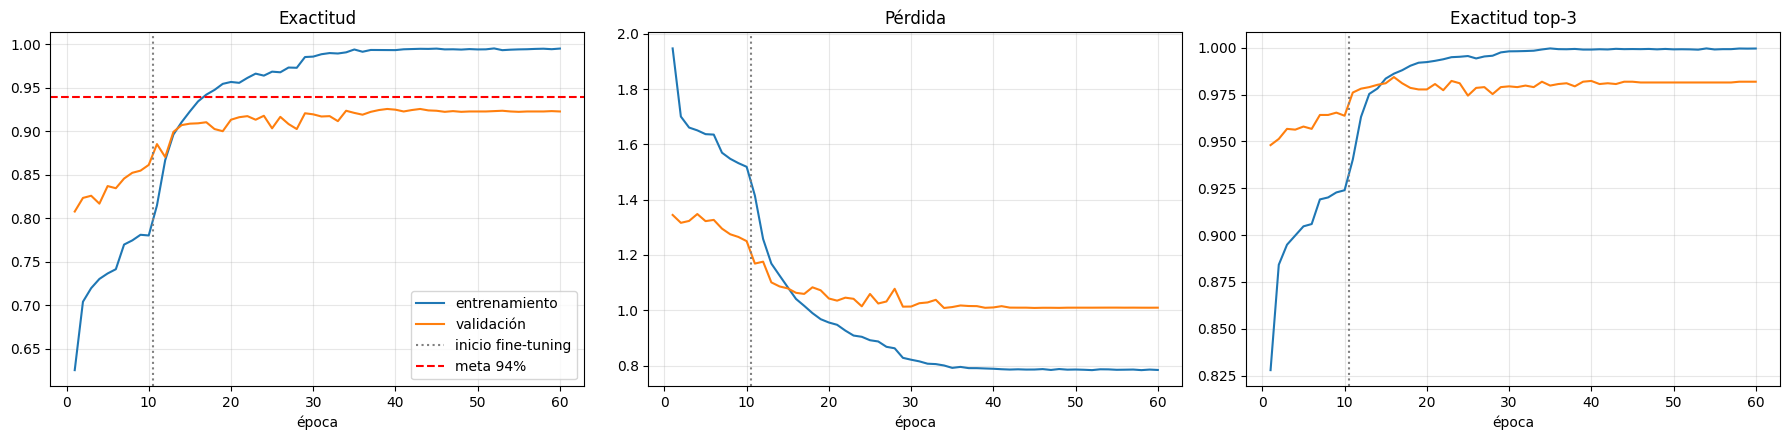

2026-10-13 06:28:31 | INFO    | Mejor época: 39 | val_accuracy 0.9257 | train_accuracy 0.9935 | brecha +0.0677


In [14]:
# 5.3 Curvas de entrenamiento y validación (las dos etapas juntas)
hist = pd.concat([pd.read_csv(SALIDA / f"historial_etapa{k}.csv").assign(etapa=k)
                  for k in (1, 2) if (SALIDA / f"historial_etapa{k}.csv").exists()])
hist = hist.drop_duplicates("epoch", keep="last").sort_values("epoch").reset_index(drop=True)
hist["epoca"] = hist["epoch"] + 1
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (m, tit) in zip(axs, [("accuracy", "Exactitud"), ("loss", "Pérdida"), ("top3", "Exactitud top-3")]):
    ax.plot(hist["epoca"], hist[m], label="entrenamiento")
    ax.plot(hist["epoca"], hist[f"val_{m}"], label="validación")
    ax.axvline(EPOCAS_ETAPA1 + 0.5, ls=":", c="gray", label="inicio fine-tuning")
    ax.set_title(tit); ax.set_xlabel("época"); ax.grid(alpha=0.3)
axs[0].axhline(META_ACCURACY, ls="--", c="red", label=f"meta {META_ACCURACY:.0%}")
axs[0].legend()
plt.tight_layout(); plt.savefig(EVI / "curvas_entrenamiento.png", dpi=110); plt.show()
mejor = hist.loc[hist["val_accuracy"].idxmax()]
log.info(f"Mejor época: {int(mejor['epoca'])} | val_accuracy {mejor['val_accuracy']:.4f} | "
         f"train_accuracy {mejor['accuracy']:.4f} | brecha {mejor['accuracy'] - mejor['val_accuracy']:+.4f}")

---
# 6. Evaluación final con el conjunto de PRUEBA (solo fotos de Colombia, nunca vistas)

In [15]:
# 6.1 Exactitud, top-3 y reporte por clase
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

modelo_eval = keras.models.load_model(SALIDA / "profesor_mejor.keras", custom_objects={"GrisAleatorio": GrisAleatorio}) if (SALIDA / "profesor_mejor.keras").exists() else profesor
def probs(ds, tta=False):                  # TTA: promedio de la foto original y su versión volteada
    p = tf.nn.softmax(modelo_eval.predict(ds, verbose=0)).numpy()
    if tta:
        pv = modelo_eval.predict(ds.map(lambda x, y: (tf.image.flip_left_right(x), y)), verbose=0)
        p = (p + tf.nn.softmax(pv).numpy()) / 2
    return p
pv0, pv1 = probs(ds_val), probs(ds_val, True)
yv = VAL["y"].values[:len(pv0)]
acc_v0, acc_v1 = float((pv0.argmax(1) == yv).mean()), float((pv1.argmax(1) == yv).mean())
USAR_TTA = acc_v1 > acc_v0                 # se decide con VALIDACIÓN, no con prueba
log.info(f"Validación: sin TTA {acc_v0:.4f} | con TTA {acc_v1:.4f} → se usa {'TTA' if USAR_TTA else 'predicción normal'}")
prob = probs(ds_test, USAR_TTA)
y_pred = prob.argmax(1)
y_true = TEST["y"].values[:len(y_pred)]
acc = accuracy_score(y_true, y_pred)
top3 = float(np.mean([t in np.argsort(p)[-3:] for t, p in zip(y_true, prob)]))
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(N_CLASES), average="macro", zero_division=0)

rep = pd.DataFrame(classification_report(y_true, y_pred, labels=range(N_CLASES), target_names=CLASES,
                                         output_dict=True, zero_division=0)).T.iloc[:N_CLASES]
rep["nombre"] = [NOMBRE[c] for c in rep.index]
rep = rep[["nombre", "precision", "recall", "f1-score", "support"]].sort_values("f1-score")
display(rep.round(3))
rep.to_csv(EVI / "reporte_por_clase.csv", encoding="utf-8-sig")

log.info("=" * 70)
log.info(f"PRUEBA ({len(y_true)} fotos de Colombia): accuracy {acc:.4f} | top-3 {top3:.4f} | "
         f"precisión macro {prec:.4f} | recall macro {rec:.4f} | F1 macro {f1:.4f}")
if "de_tolima" in TEST.columns and TEST["de_tolima"].fillna(False).astype(bool).any():
    m_t = TEST["de_tolima"].fillna(False).astype(bool).values[:len(y_pred)]
    log.info(f"   Subconjunto del Tolima: {int(m_t.sum())} fotos | accuracy {accuracy_score(y_true[m_t], y_pred[m_t]):.4f}")
log.info(("✅ CUMPLE" if acc >= META_ACCURACY else "❌ NO CUMPLE TODAVÍA") + f" la meta de {META_ACCURACY:.0%}")

2026-10-13 06:29:27 | INFO    | Validación: sin TTA 0.9257 | con TTA 0.9241 → se usa predicción normal


,nombre,precision,recall,f1-score,support
neque_negro,Ñeque negro,0.486,0.515,0.500,33.0
mono_ardilla_ecuatoriano,Mono ardilla ecuatoriano,0.775,0.756,0.765,41.0
mapache_cangrejero,Mapache cangrejero,0.815,0.815,0.815,27.0
mono_ardilla,Mono ardilla,0.817,0.845,0.831,58.0
armadillo_coletrapo,Armadillo coletrapo,0.833,0.833,0.833,12.0
tamandua_sureno,Tamandúa sureño,0.872,0.820,0.845,50.0
zaino,Zaino,0.860,0.843,0.851,51.0
danta,Danta,0.769,0.968,0.857,31.0
neque,Ñeque,0.876,0.863,0.870,139.0
tamandua,Tamandúa,0.906,0.842,0.873,57.0


2026-10-13 06:29:48 | INFO    | ======================================================================
2026-10-13 06:29:48 | INFO    | PRUEBA (2458 fotos de Colombia): accuracy 0.9312 | top-3 0.9821 | precisión macro 0.9125 | recall macro 0.9164 | F1 macro 0.9134
2026-10-13 06:29:48 | INFO    |    Subconjunto del Tolima: 13 fotos | accuracy 0.7692
2026-10-13 06:29:48 | INFO    | ❌ NO CUMPLE TODAVÍA la meta de 94%


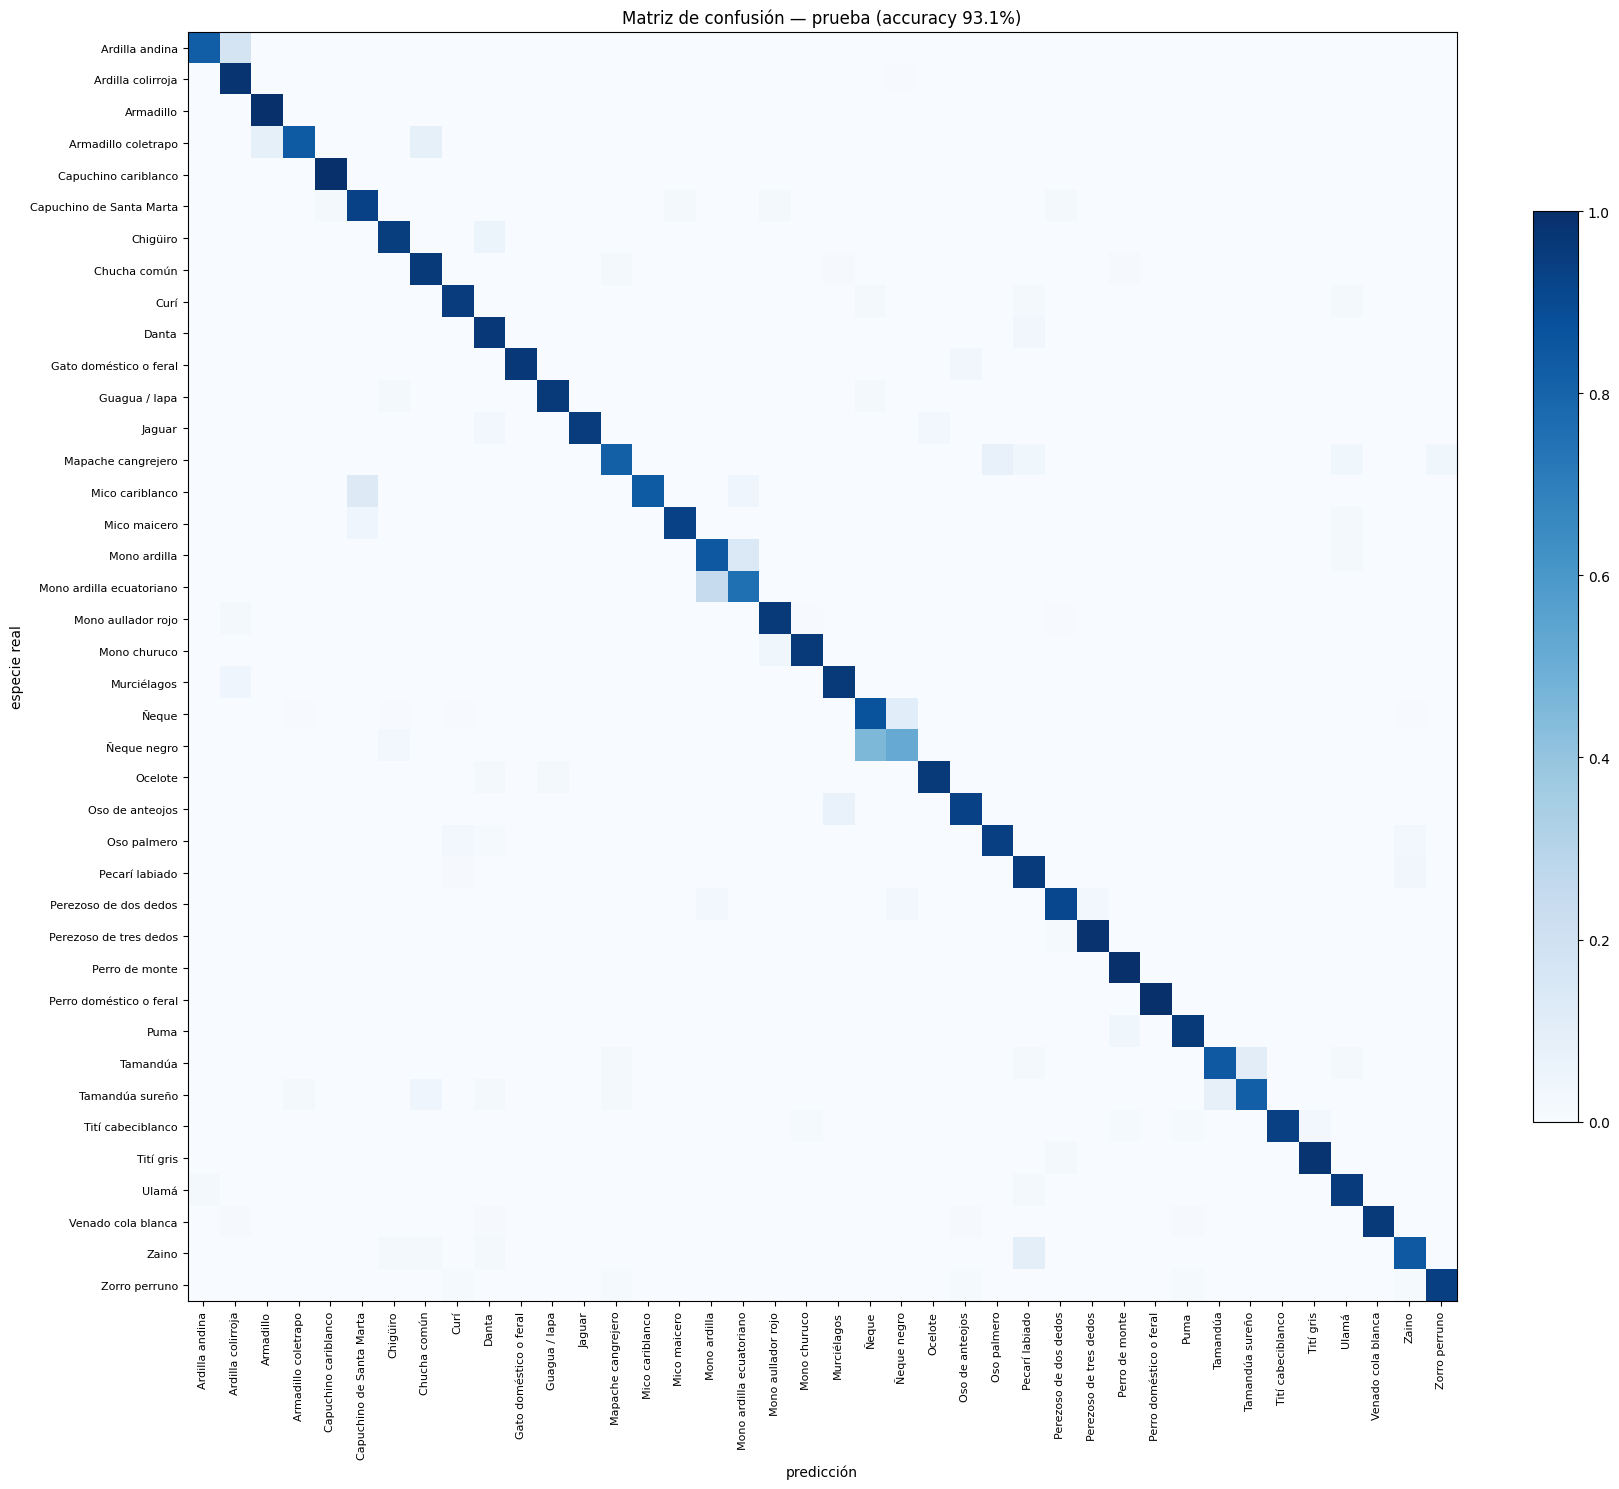

,errores,especie real,confundida con
0,15,Ñeque negro,Ñeque
1,15,Ñeque,Ñeque negro
2,10,Mono ardilla ecuatoriano,Mono ardilla
3,8,Mono ardilla,Mono ardilla ecuatoriano
4,6,Tamandúa,Tamandúa sureño
5,6,Ardilla andina,Ardilla colirroja
6,5,Zaino,Pecarí labiado
7,4,Tamandúa sureño,Tamandúa
8,3,Pecarí labiado,Zaino
9,3,Murciélagos,Ardilla colirroja


In [16]:
# 6.2 Matriz de confusión (normalizada por fila) y pares de especies que más se confunden
cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASES))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(17, 15))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASES)); ax.set_yticks(range(N_CLASES))
ax.set_xticklabels([NOMBRE[c] for c in CLASES], rotation=90, fontsize=8)
ax.set_yticklabels([NOMBRE[c] for c in CLASES], fontsize=8)
ax.set_xlabel("predicción"); ax.set_ylabel("especie real")
ax.set_title(f"Matriz de confusión — prueba (accuracy {acc:.1%})"); plt.colorbar(im, fraction=0.03)
plt.tight_layout(); plt.savefig(EVI / "matriz_confusion.png", dpi=110); plt.show()

pares = sorted([(int(cm[i, j]), NOMBRE[CLASES[i]], NOMBRE[CLASES[j]]) for i in range(N_CLASES) for j in range(N_CLASES)
                if i != j and cm[i, j] > 0], reverse=True)[:12]
conf = pd.DataFrame(pares, columns=["errores", "especie real", "confundida con"])
display(conf); conf.to_csv(EVI / "pares_mas_confundidos.csv", index=False, encoding="utf-8-sig")

In [17]:
# 6.3 Guardar el modelo final, las etiquetas y el resumen (evidencia para el póster)
profesor_final = SALIDA / "profesor_final.keras"
modelo_eval.save(profesor_final)
json.dump({"clases": CLASES, "nombres": [NOMBRE[c] for c in CLASES], "img_size": IMG_SIZE,
           "entrada": "RGB 0..255 (el modelo normaliza por dentro)", "salida": "logits (aplicar softmax)"},
          open(SALIDA / "etiquetas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
resumen_final = {
    "fecha": datetime.now().isoformat(timespec="seconds"), "modelo": MODELO_BASE, "img_size": IMG_SIZE,
    "clases": N_CLASES, "imagenes": {k: int((meta.split == k).sum()) for k in ["train", "val", "test", "sin_usar"]},
    "epocas_ejecutadas": int(hist["epoca"].max()), "mejor_epoca": int(mejor["epoca"]),
    "dropout": [DROPOUT_1, DROPOUT_2], "regularizacion": f"{REGULARIZACION} {FACTOR_REG}",
    "label_smoothing": LABEL_SMOOTHING, "lr": [LR_ETAPA1, LR_ETAPA2], "paciencia_earlystopping": PACIENCIA,
    "test_accuracy": round(acc, 4), "test_top3": round(top3, 4), "test_f1_macro": round(float(f1), 4),
    "meta": META_ACCURACY, "cumple_meta": bool(acc >= META_ACCURACY),
    "tamano_modelo_MB": round(profesor_final.stat().st_size / 1e6, 1),
}
json.dump(resumen_final, open(EVI / "resumen_entrenamiento.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
display(pd.Series(resumen_final).to_frame("valor"))
log.info(f"Modelo guardado: {profesor_final} ({resumen_final['tamano_modelo_MB']} MB)")

,valor
fecha,2026-10-13T06:29:53
modelo,EfficientNetV2S
img_size,260
clases,40
imagenes,"{'train': 17960, 'val': 2424, 'test': 2458, 's..."
epocas_ejecutadas,60
mejor_epoca,39
dropout,"[0.4, 0.3]"
regularizacion,l2 0.0001
label_smoothing,0.1


2026-10-13 06:29:53 | INFO    | Modelo guardado: /kaggle/working/entrenamiento/profesor_final.keras (368.7 MB)


---
# 7. Lo que sigue (Fase C)
1. **Regularización L1 vs. L2** — comparación con el mismo modelo (defensa técnica).
2. **Destilación de conocimiento:** el modelo profesor (EfficientNetV2-S) enseña a un **estudiante MobileNetV3** liviano.
3. **Conversión a TensorFlow Lite** (tamaño y latencia) para usarlo desde una **aplicación móvil**.
4. **Ensamble de modelos vs. modelo destilado.**
5. **Pruebas de campo** con fotos reales de cámaras trampa del Tolima.